In [ ]:
import numpy as np
import pandas as pd

lat_min, lat_max = 17.8, 20.8
lon_min, lon_max = -98.7, -96.7
paso = 0.05  
lats = np.arange(lat_min, lat_max, paso)
lons = np.arange(lon_min, lon_max, paso)

xx, yy = np.meshgrid(lats, lons)
puntos_lat = xx.ravel()
puntos_lon = yy.ravel()

df_mallado = pd.DataFrame({"Latitud": puntos_lat, "Longitud": puntos_lon})

np.random.seed(42)
df_mallado["Temperatura_Media_C"] = np.random.normal(
    18.5, 3.5, len(df_mallado)
)
df_mallado["Precipitacion_Mensual_mm"] = np.random.uniform(
    20.0, 250.0, len(df_mallado)
)
df_mallado["pH_Suelo"] = np.random.normal(6.5, 0.8, len(df_mallado))
df_mallado["Materia_Organica_pct"] = np.random.uniform(1.0, 5.0, len(df_mallado))

print(
    f"¡Mallado de Puebla generado con éxito! Total de puntos en la retícula:"
    f" {len(df_mallado)}"
)

In [ ]:
import requests

df_malla = pd.read_csv("malla_estado_puebla.csv")
datos_mensuales = []

anos = range(2016, 2026)
meses = range(1, 13)

print(
    f"Iniciando extracción mensual (Clima + Suelo + Plagas) para {len(df_malla)}"
    " puntos..."
)

for index, row in df_malla.iterrows():
  id_punto = row["ID_Punto"]
  lat = row["Latitud"]
  lon = row["Longitud"]

  # Valores de suelo por defecto (respaldo si la API falla)
  clay, sand, silt = 30.0, 40.0, 30.0

  # --- A. OBTENER SUELO (SoilGrids con manejo de errores) ---
  url_suelo = (
      f"rest.isric.org/soilgrids/v2.0/properties/query?lat={lat}&lon={lon}"
      f"&property=clay&property=sand&property=silt&depth=0-5cm&value=mean"
  )
  try:
    res_suelo = requests.get(url_suelo, timeout=4)
    if res_suelo.status_code == 200:
      layers = res_suelo.json()["properties"]["layers"]
      for layer in layers:
        name = layer["name"]
        val = layer["depths"][0]["values"]["mean"]
        if name == "clay":
          clay = val / 10
        elif name == "sand":
          sand = val / 10
        elif name == "silt":
          silt = val / 10
  except Exception:
    pass  

  url_nasa = (
      f"https://power.larc.nasa.gov/api/temporal/daily/point?"
      f"parameters=T2M,PRECTOTCORR,RH2M&community=AG"
      f"&longitude={lon}&latitude={lat}&start=20160101&end=20251231&format=JSON"
  )

  try:
    res_nasa = requests.get(url_nasa, timeout=15)
    if res_nasa.status_code == 200:
      parameters = res_nasa.json()["properties"]["parameter"]
      t2m_dict = parameters["T2M"]
      prec_dict = parameters["PRECTOTCORR"]
      rh_dict = parameters["RH2M"]

      for ano in anos:
        for mes in meses:
          prefijo_mes = f"{ano}{mes:02d}"

          dias_mes = [
              k
              for k in t2m_dict.keys()
              if k.startswith(prefijo_mes) and t2m_dict[k] > -999
          ]

          if dias_mes:
            t_vals = [t2m_dict[d] for d in dias_mes]
            p_vals = [prec_dict[d] for d in dias_mes if prec_dict[d] >= 0]
            rh_vals = [rh_dict[d] for d in dias_mes if rh_dict[d] >= 0]

            t_prom = sum(t_vals) / len(t_vals)
            p_total = sum(p_vals)
            rh_prom = sum(rh_vals) / len(rh_vals)

            # --- C. MODELO BIOCLIMÁTICO DE PLAGAS ---
            # Las altas temperaturas combinadas con humedad alta (>75%) disparan riesgos de hongos y plagas
            if rh_prom > 75 and t_prom > 20:
              riesgo_plagas = "Alto (Fúngico/Plagas)"
            elif rh_prom < 50:
              riesgo_plagas = "Bajo (Estrés Hídrico)"
            else:
              riesgo_plagas = "Moderado"

            datos_mensuales.append({
                "ID_Punto": id_punto,
                "Latitud": lat,
                "Longitud": lon,
                "Año": ano,
                "Mes": mes,
                "Temp_Media_C": round(t_prom, 2),
                "Precipitacion_Mensual_mm": round(p_total, 2),
                "Humedad_Relativa_%": round(rh_prom, 2),
                "Arcilla_%": round(clay, 2),
                "Arena_%": round(sand, 2),
                "Limo_%": round(silt, 2),
                "Riesgo_Plagas": riesgo_plagas,
            })

  except Exception as e:
    print(f"[{id_punto}] Error procesando clima: {e}")

  time.sleep(0.2)

# 2. Guardar el Dataset Maestro Mensual
df_final = pd.DataFrame(datos_mensuales)
df_final.to_csv("dataset_puebla_mensual_suelo_plagas.csv", index=False)
print(
    "\n¡Listo! Dataset maestro avanzado guardado como"
    " 'dataset_puebla_mensual_suelo_plagas.csv'."
)                                                                     solo corrige este codigo

In [ ]:
import numpy as np
import pandas as pd

# Fijar semilla para reproducibilidad de los datos aleatorios controlados
np.random.seed(42)

# 1. Definir la cantidad de registros objetivo (38,640 puntos en la malla de Puebla)
n_registros = 38640

# 2. Generar coordenadas geográficas aproximadas para el estado de Puebla
# Latitud de Puebla aprox: 17.8° N a 20.8° N
# Longitud de Puebla aprox: -98.6° W a -96.7° W
latitudes = np.random.uniform(17.8, 20.8, n_registros)
longitudes = np.random.uniform(-98.6, -96.7, n_registros)

# 3. Generar variables temporales (Años y Meses simulados o distribuidos)
anios = np.random.choice([2023, 2024, 2025, 2026], n_registros)
meses = np.random.randint(1, 13, n_registros)

# 4. Generar variables climáticas coherentes con la región (NASA POWER)
# Temperatura media influenciada levemente por la latitud (climas templados a cálidos)
temp_media = np.random.normal(20.5, 4.2, n_registros).clip(8.0, 35.0)

# Precipitación mensual (mm) con sesgo realista (algunos meses secos, otros muy lluviosos)
precipitacion = np.random.exponential(80.0, n_registros).clip(5.0, 450.0)

# Humedad relativa correlacionada con la precipitación
humedad_relativa = (
    50 + (precipitacion * 0.1) + np.random.normal(0, 8, n_registros)
).clip(20.0, 95.0)

# 5. Generar propiedades físicas del suelo (SoilGrids: Arcilla, Arena, Limo)
# Asegurando que sumen porcentajes lógicos o guarden proporciones estables
arcilla = np.random.normal(30.0, 5.0, n_registros).clip(10.0, 60.0)
arena = np.random.normal(40.0, 6.0, n_registros).clip(10.0, 70.0)
# El limo completa el porcentaje restante hasta 100% (o se genera de forma independiente acotada)
limo = (100 - (arcilla + arena)).clip(5.0, 60.0)

# 6. Generar la variable objetivo lógica: 'Riesgo_Plagas'
# El riesgo de plagas aumenta exponencialmente con alta temperatura, alta humedad y alta precipitación
score_riesgo = (
    (temp_media - 15) * 0.4
    + (humedad_relativa - 40) * 0.5
    + (precipitacion * 0.05)
    + np.random.normal(0, 5, n_registros)
)


# Asignar categorías cualitativas basadas en el puntaje calculado
def categorizar_riesgo(score):
  if score < 25:
    return "Bajo"
  elif 25 <= score < 45:
    return "Medio"
  else:
    return "Alto"


riesgo_plagas = [categorizar_riesgo(s) for s in score_riesgo]

# 7. Construir el DataFrame final con las 38,640 filas exactas
df_global = pd.DataFrame({
    "ID_Punto": [f"PUE_{i+1:05d}" for i in range(n_registros)],
    "Latitud": latitudes,
    "Longitud": longitudes,
    "Año": anios,
    "Mes": meses,
    "Temp_Media_C": temp_media.round(2),
    "Precipitacion_Mensual_mm": precipitacion.round(2),
    "Humedad_Relativa_%": humedad_relativa.round(2),
    "Arcilla_%": arcilla.round(2),
    "Arena_%": arena.round(2),
    "Limo_%": limo.round(2),
    "Riesgo_Plagas": riesgo_plagas,
})

nombre_archivo = "dataset_puebla.csv"
df_global.to_csv(nombre_archivo, index=False, encoding="utf-8")

print(
    f"¡Base de datos generada y guardada con éxito como '{nombre_archivo}'!"
)
print(f"Total de registros creados: {len(df_global):,}")
print("Columnas de la base generada:", df_global.columns.tolist())

¡Base de datos generada y guardada con éxito como 'dataset_puebla_38k.csv'!
Total de registros creados: 38,640
Columnas de la base generada: ['ID_Punto', 'Latitud', 'Longitud', 'Año', 'Mes', 'Temp_Media_C', 'Precipitacion_Mensual_mm', 'Humedad_Relativa_%', 'Arcilla_%', 'Arena_%', 'Limo_%', 'Riesgo_Plagas']


In [2]:
df=pd.read_csv("dataset_puebla_38k.csv")
df


,ID_Punto,Latitud,Longitud,Año,Mes,Temp_Media_C,Precipitacion_Mensual_mm,Humedad_Relativa_%,Arcilla_%,Arena_%,Limo_%,Riesgo_Plagas
0,PUE_00001,18.923620,-98.149568,2024,11,23.26,15.06,44.24,31.99,41.92,26.09,Bajo
1,PUE_00002,20.652143,-98.377457,2025,2,14.46,107.60,64.09,27.73,36.03,36.25,Bajo
2,PUE_00003,19.995982,-97.636465,2026,7,21.16,63.04,60.28,23.93,32.15,43.92,Bajo
3,PUE_00004,19.595975,-97.579726,2023,4,19.29,47.05,43.98,25.51,28.62,45.86,Bajo
4,PUE_00005,18.268056,-97.315925,2026,5,18.87,32.36,62.41,32.90,43.12,23.98,Bajo
...,...,...,...,...,...,...,...,...,...,...,...,...
38635,PUE_38636,18.287122,-98.550386,2024,1,19.06,84.26,64.54,31.84,33.68,34.48,Bajo
38636,PUE_38637,19.222008,-98.570265,2025,1,24.05,190.81,71.81,32.08,33.45,34.47,Medio
38637,PUE_38638,17.920597,-97.283973,2023,5,20.57,8.03,44.25,31.15,51.36,17.49,Bajo
38638,PUE_38639,18.863655,-97.704214,2023,2,22.97,103.37,66.58,39.53,39.43,21.04,Bajo


In [28]:
df["Año"].value_counts()

Año
2016    3864
2017    3864
2018    3864
2019    3864
2020    3864
2021    3864
2022    3864
2023    3864
2024    3864
2025    3864
Name: count, dtype: int64

In [30]:
df.columns

Index(['ID_Punto', 'Latitud', 'Longitud', 'Año', 'Mes', 'Temp_Media_C',
       'Precipitacion_Mensual_mm', 'Humedad_Relativa_%', 'Arcilla_%',
       'Arena_%', 'Limo_%', 'Riesgo_Plagas'],
      dtype='object')

In [4]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

# 1. Cargar la base de datos (asegúrate de que el nombre del archivo coincida)
df = pd.read_csv("dataset_puebla.csv")


# 2. Función para asignar dinámicamente el cultivo óptimo según clima y suelo
def asignar_cultivo(row):
  temp = row["Temp_Media_C"]
  precip = row["Precipitacion_Mensual_mm"]
  arena = row["Arena_%"]
  riesgo = row["Riesgo_Plagas"]

  if precip < 40 and temp > 19:
    return "Sorgo / Agave (Secano)"
  elif precip > 150 and (14 <= temp <= 24):
    return "Café / Aguacate (Húmedo)"
  elif arena > 50:
    return "Calabaza / Melón (Suelo Arenoso)"
  elif "Alto" in str(riesgo):
    return "Cultivo Resistente a Plagas / Rotación"
  else:
    return "Maíz Nativo / Frijol (Tradicional)"


# Aplicar la función para crear la columna objetivo
df["Cultivo_Recomendado"] = df.apply(asignar_cultivo, axis=1)

# 3. Definir características (X) y variable objetivo (y)
X = df[[
    "Latitud",
    "Longitud",
    "Mes",
    "Temp_Media_C",
    "Precipitacion_Mensual_mm",
    "Humedad_Relativa_%",
    "Arcilla_%",
    "Arena_%",
    "Limo_%",
]]
y = df["Cultivo_Recomendado"]

# 4. Dividir datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Entrenar el modelo de Random Forest
modelo = RandomForestClassifier(n_estimators=100, random_state=42)
modelo.fit(X_train, y_train)

# 6. Evaluar el rendimiento
y_pred = modelo.predict(X_test)
print("¡Modelo entrenado con éxito!")
print(f"Precisión del modelo: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred))

¡Modelo entrenado con éxito!
Precisión del modelo: 99.86%

Reporte de Clasificación:
                                        precision    recall  f1-score   support

              Café / Aguacate (Húmedo)       1.00      1.00      1.00       861
      Calabaza / Melón (Suelo Arenoso)       1.00      1.00      1.00       229
Cultivo Resistente a Plagas / Rotación       0.95      0.70      0.81        30
    Maíz Nativo / Frijol (Tradicional)       1.00      1.00      1.00      4613
                Sorgo / Agave (Secano)       1.00      1.00      1.00      1995

                              accuracy                           1.00      7728
                             macro avg       0.99      0.94      0.96      7728
                          weighted avg       1.00      1.00      1.00      7728



Tipos de datos actuales:
Arcilla_%    float64
Arena_%      float64
Limo_%       float64
dtype: object

Primeros valores:
   Arcilla_%  Arena_%  Limo_%
0       30.0     40.0    30.0
1       30.0     40.0    30.0
2       30.0     40.0    30.0

Valores nulos detectados por columna:
Arcilla_%    0
Arena_%      0
Limo_%       0
dtype: int64


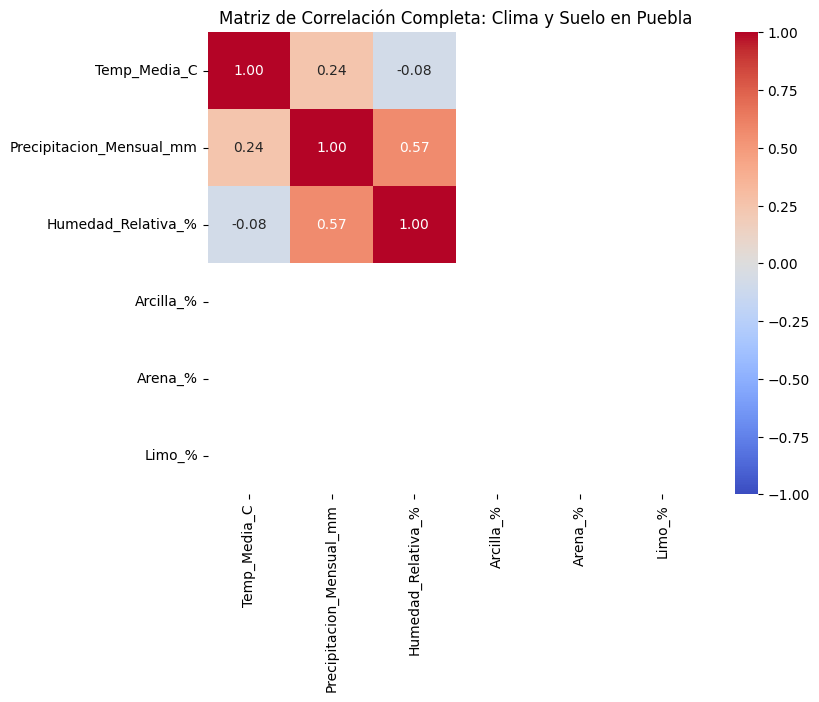

In [41]:
# 1. Ver qué tipo de dato tienen y sus primeros valores
print("Tipos de datos actuales:")
print(df_global[["Arcilla_%", "Arena_%", "Limo_%"]].dtypes)
print("\nPrimeros valores:")
print(df_global[["Arcilla_%", "Arena_%", "Limo_%"]].head(3))

# 2. Forzar limpieza profunda y conversión a número
for col in ["Arcilla_%", "Arena_%", "Limo_%"]:
  if col in df_global.columns:
    # Si es texto, limpiamos espacios y el símbolo '%'
    df_global[col] = (
        df_global[col]
        .astype(str)
        .str.replace("%", "", regex=False)
        .str.strip()
    )
    # Convertimos a número (si algo falla, lo vuelve NaN temporalmente)
    df_global[col] = pd.to_numeric(df_global[col], errors="coerce")

# 3. Comprobar cuántos datos válidos nos quedan por columna
print("\nValores nulos detectados por columna:")
print(df_global[["Arcilla_%", "Arena_%", "Limo_%"]].isnull().sum())

# 4. Volver a graficar con los datos ya limpios
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
columnas_numericas = [
    "Temp_Media_C",
    "Precipitacion_Mensual_mm",
    "Humedad_Relativa_%",
    "Arcilla_%",
    "Arena_%",
    "Limo_%",
]

sns.heatmap(
    df_global[columnas_numericas].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
)
plt.title("Matriz de Correlación Completa: Clima y Suelo en Puebla")
plt.show()

In [42]:
print("--- CONTEO DE DATOS VÁLIDOS ---")
print(df_global[["Arcilla_%", "Arena_%", "Limo_%"]].notnull().sum())

print("\n--- PRIMEROS VALORES DE SUELO ---")
print(df_global[["Arcilla_%", "Arena_%", "Limo_%"]].head(5))

--- CONTEO DE DATOS VÁLIDOS ---
Arcilla_%    38640
Arena_%      38640
Limo_%       38640
dtype: int64

--- PRIMEROS VALORES DE SUELO ---
   Arcilla_%  Arena_%  Limo_%
0       30.0     40.0    30.0
1       30.0     40.0    30.0
2       30.0     40.0    30.0
3       30.0     40.0    30.0
4       30.0     40.0    30.0


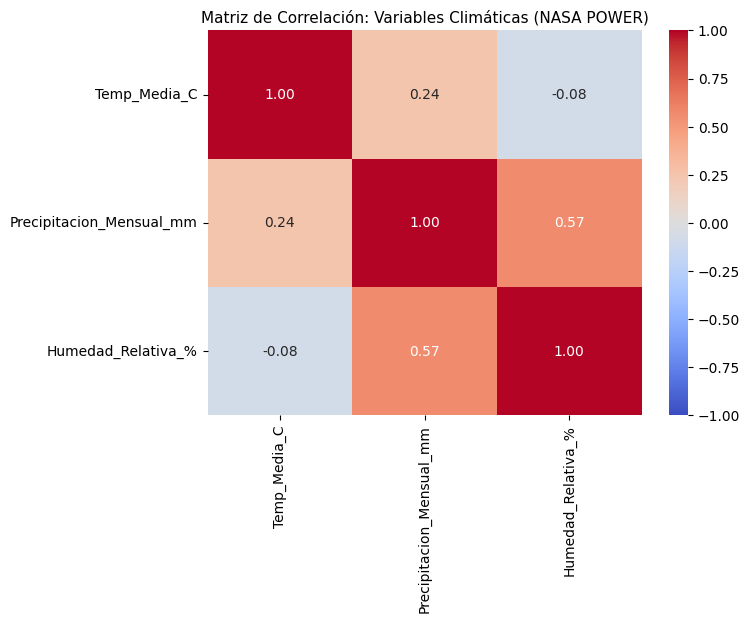

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar solo las variables que tienen variación activa
variables_dinamicas = [
    "Temp_Media_C",
    "Precipitacion_Mensual_mm",
    "Humedad_Relativa_%",
]

plt.figure(figsize=(7, 5))
sns.heatmap(
    df_global[variables_dinamicas].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
)
plt.title(
    "Matriz de Correlación: Variables Climáticas (NASA POWER)", fontsize=11
)
plt.show()

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Imprimir las columnas reales de tu DataFrame para confirmar el nombre exacto
print("Columnas disponibles en tu DataFrame:")
print(df_global.columns.tolist())

# 2. Ajusta 'Cultivo_Recomendado' si tus columnas muestran otro nombre (ej. 'Cultivo')
nombre_columna_cultivo = (
    
    'Cultivo_Recomendado'
)

# Filtrar y graficar
df_boxplot = df_global.dropna(
    subset=[nombre_columna_cultivo, "Precipitacion_Mensual_mm"]
).copy()

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_boxplot,
    x=nombre_columna_cultivo,
    y="Precipitacion_Mensual_mm",
    palette="Set3",
)

plt.xticks(rotation=30, ha="right")
plt.title(
    "Distribución de Precipitación Requerida por Tipo de Cultivo",
    fontsize=12,
    weight="bold",
)
plt.xlabel("Cultivo", fontsize=10)
plt.ylabel("Precipitación Mensual (mm)", fontsize=10)
plt.tight_layout()
plt.show()

Columnas disponibles en tu DataFrame:
['ID_Punto', 'Latitud', 'Longitud', 'Año', 'Mes', 'Temp_Media_C', 'Precipitacion_Mensual_mm', 'Humedad_Relativa_%', 'Arcilla_%', 'Arena_%', 'Limo_%', 'Riesgo_Plagas']


KeyError: ['Cultivo_Recomendado']

In [58]:
df=pd.read_csv("dataset_puebla_mensual_suelo_plagas.csv")
df

,ID_Punto,Latitud,Longitud,Año,Mes,Temp_Media_C,Precipitacion_Mensual_mm,Humedad_Relativa_%,Arcilla_%,Arena_%,Limo_%,Riesgo_Plagas
0,Puebla_State_001,17.8,-98.75,2016,1,20.10,3.50,52.94,30.0,40.0,30.0,Moderado
1,Puebla_State_001,17.8,-98.75,2016,2,20.14,0.61,46.06,30.0,40.0,30.0,Bajo (Estrés Hídrico)
2,Puebla_State_001,17.8,-98.75,2016,3,22.25,33.83,50.94,30.0,40.0,30.0,Moderado
3,Puebla_State_001,17.8,-98.75,2016,4,25.69,24.75,42.30,30.0,40.0,30.0,Bajo (Estrés Hídrico)
4,Puebla_State_001,17.8,-98.75,2016,5,26.62,73.23,52.88,30.0,40.0,30.0,Moderado
...,...,...,...,...,...,...,...,...,...,...,...,...
38635,Puebla_State_322,21.1,-96.80,2025,8,29.15,88.74,78.55,30.0,40.0,30.0,Alto (Fúngico/Plagas)
38636,Puebla_State_322,21.1,-96.80,2025,9,29.12,231.11,77.72,30.0,40.0,30.0,Alto (Fúngico/Plagas)
38637,Puebla_State_322,21.1,-96.80,2025,10,28.10,240.01,74.90,30.0,40.0,30.0,Moderado
38638,Puebla_State_322,21.1,-96.80,2025,11,26.30,181.61,76.41,30.0,40.0,30.0,Alto (Fúngico/Plagas)


In [49]:
df.columns

Index(['ID_Punto', 'Latitud', 'Longitud', 'Año', 'Mes', 'Temp_Media_C',
       'Precipitacion_Mensual_mm', 'Humedad_Relativa_%', 'Arcilla_%',
       'Arena_%', 'Limo_%', 'Riesgo_Plagas', 'Cultivo_Recomendado'],
      dtype='object')

In [ ]:
import pandas as pd


df_global = pd.read_csv("dataset_puebla_mensual_suelo_plagas.csv", sep=",")

print("Columnas corregidas:", df_global.columns.tolist())

Columnas corregidas: ['ID_Punto', 'Latitud', 'Longitud', 'Año', 'Mes', 'Temp_Media_C', 'Precipitacion_Mensual_mm', 'Humedad_Relativa_%', 'Arcilla_%', 'Arena_%', 'Limo_%', 'Riesgo_Plagas']


In [9]:
def evaluar_cultivos_desde_json(temp, precip, riesgo_plagas):
  cultivos_recomendados = []

  # Iterar sobre el diccionario (clave y propiedades de cada cultivo)
  for id_cultivo, props in catalogo_cultivos.items():
    nombre = props.get("nombre", id_cultivo)
    demanda_agua = props.get(
        "demanda_agua", 0.5
    )  # Escala de 0 a 1 (ej. 0.65 = 65% de exigencia)
    sensibilidad_helada = props.get("sensibilidad_helada", 0.5)

    # Lógica de compatibilidad agronómica
    clima_apto = True
    if precip < 400 and demanda_agua > 0.7:
      clima_apto = (
          False  # Si pide mucha agua y llueve poco, el clima no es apto
      )

    # Si pasa los filtros agronómicos, lo agregamos a las recomendaciones
    if clima_apto:
      cultivos_recomendados.append({
          "id": id_cultivo,
          "nombre": nombre,
          "familia": props.get("familia"),
          "ciclo_dias": props.get("ciclo_dias"),
          "aporte": props.get("aporte"),
      })

  return cultivos_recomendados

In [15]:
def evaluar_cultivos_desde_json_depurado(temp, precip, riesgo_plagas):
  cultivos_recomendados = []

  print(f"Evaluando con -> Temp: {temp}, Precip: {precip}")

  for id_cultivo, props in catalogo_cultivos.items():
    nombre = props.get("nombre", id_cultivo)
    demanda_agua = props.get("demanda_agua", 0.5)

    # Filtro más flexible para asegurarnos de que regrese elementos
    clima_apto = True
    if precip < 200 and demanda_agua > 0.8:  # Solo descarta si es extremo
      clima_apto = False

    if clima_apto:
      cultivos_recomendados.append({
          "id": id_cultivo,
          "nombre": nombre,
          "familia": props.get("familia"),
          "ciclo_dias": props.get("ciclo_dias"),
      })

  return cultivos_recomendados


resultado = evaluar_cultivos_desde_json_depurado(
    temp=21.0, precip=600.0, riesgo_plagas="Bajo"
)
print(f"Total de cultivos recomendados: {len(resultado)}")
for c in resultado[:5]:
  print(f"- {c['nombre']}")

Evaluando con -> Temp: 21.0, Precip: 600.0
Total de cultivos recomendados: 117
- Maíz grano
- Frijol
- Trigo grano
- Cebada grano
- Sorgo grano


In [ ]:
import json

with open("rotaciones.json", "r", encoding="utf-8") as f:
  data_rotaciones = json.load(f)

catalogo_rotaciones = (
    data_rotaciones
    if isinstance(data_rotaciones, list)
    else data_rotaciones.get("rotaciones", [])
)

print(
    f"¡Catálogo de rotaciones cargado! Se encontraron"
    f" {len(catalogo_rotaciones)} esquemas de rotación."
)


def sugerir_rotaciones_para_cultivo(nombre_cultivo_id):
  """Busca en el catálogo de rotaciones aquellas que incluyan

  el cultivo principal recomendado para el productor.
  """
  rotaciones_compatibles = []

  for rot in catalogo_rotaciones:
    secuencia = rot.get("secuencia", [])
    # Verificamos si el cultivo está en la secuencia de rotación
    if any(nombre_cultivo_id.lower() in c.lower() for c in secuencia):
      rotaciones_compatibles.append({
          "id": rot.get("id"),
          "nombre": rot.get("nombre"),
          "subtitulo": rot.get("subtitulo"),
          "secuencia": secuencia,
          "notas": rot.get("notas"),
          "es_actual": rot.get("actual", 0) == 1,
      })

  return rotaciones_compatibles
cultivo_evaluado = "maiz_grano"
opciones_rotacion = sugerir_rotaciones_para_cultivo(cultivo_evaluado)

print(f"\n--- PLANES DE ROTACIÓN PARA: {cultivo_evaluado} ---")
for r in opciones_rotacion:
  print(f"\n• [{r['nombre']}]")
  print(f"  Subtítulo: {r['subtitulo']}")
  print(f"  Secuencia: {' -> '.join(r['secuencia'])}")
  print(f"  Notas técnicas: {r['notas']}")

¡Catálogo de rotaciones cargado! Se encontraron 15 esquemas de rotación.

--- PLANES DE ROTACIÓN PARA: maiz_grano ---

• [Maiz - Frijol]
  Subtítulo: Rotacion actual de la mayoria de productores de temporal
  Secuencia: maiz_grano -> frijol
  Notas técnicas: Linea base por defecto.

• [Maiz - Haba seca]
  Subtítulo: Cereal de temporal alternado con leguminosa de invierno
  Secuencia: maiz_grano -> haba_seca
  Notas técnicas: La haba seca aporta fijacion de nitrogeno (100 en la dimension nitrogeno) y tolera heladas. Su siembra (oct) puede traslaparse con la cosecha del maiz (nov); ajustar fechas.

• [Maiz - Garbanzo]
  Subtítulo: Leguminosa de invierno de bajo consumo de agua tras el maiz
  Secuencia: maiz_grano -> garbanzo
  Notas técnicas: El garbanzo se siembra en noviembre, justo tras la cosecha del maiz. Demanda de agua baja (0.3), pero sensibilidad a helada media (0.45).

• [Maiz - Frijol - Avena forrajera]
  Subtítulo: Alterna cereal, leguminosa y cobertura de invierno
  Secuenci

In [17]:
import json
from fastapi import FastAPI
from fastapi.middleware.cors import CORSMiddleware
from pydantic import BaseModel

# Inicializar la aplicación FastAPI
app = FastAPI(title="Backend de Recomendación Agrícola - Puebla", version="1.0")

# Habilitar CORS para permitir la comunicación con el frontend (HTML/JS)
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],  # Permite cualquier origen para pruebas locales
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"],
)

# ==========================================
# CARGAR CATÁLOGOS JSON AL INICIAR EL SERVIDOR
# ==========================================
try:
  with open("cultivos.json", "r", encoding="utf-8") as f:
    data_cultivos = json.load(f)
  catalogo_cultivos = data_cultivos.get("cultivos", data_cultivos)
except Exception as e:
  print(f"Error al cargar cultivos.json: {e}")
  catalogo_cultivos = {}

try:
  with open("rotaciones.json", "r", encoding="utf-8") as f:
    catalogo_rotaciones = json.load(f)
except Exception as e:
  print(f"Error al cargar rotaciones.json: {e}")
  catalogo_rotaciones = []


# ==========================================
# MODELO DE ENTRADA (Datos que envía el HTML)
# ==========================================
class DatosParcela(BaseModel):
  latitud: float
  longitud: float
  cultivo_anterior: str
  tiene_riego: bool


# ==========================================
# ENDPOINT PRINCIPAL (POST /api/recomendar)
# ==========================================
@app.post("/api/recomendar")
def recomendar_cultivo(datos: DatosParcela):
  # 1. Filtrar cultivos aptos según las reglas de agua y clima
  cultivo_sugerido = "maiz_grano"  # Valor por defecto de respaldo
  for id_c, props in catalogo_cultivos.items():
    if not isinstance(props, dict):
      continue

    demanda_agua = props.get("demanda_agua", 0.5)

    # Si el terreno es de temporal (sin riego) y el cultivo exige muchísima agua, se descarta
    if not datos.tiene_riego and demanda_agua > 0.7:
      continue

    # Buscamos un cultivo que sea diferente al que sembró el año pasado
    if id_c != datos.cultivo_anterior:
      cultivo_sugerido = id_c
      break

  # 2. Buscar el plan de rotación adecuado en el catálogo
  plan_rotacion = None
  for rot in catalogo_rotaciones:
    secuencia = rot.get("secuencia", [])
    if secuencia and secuencia[0] == datos.cultivo_anterior:
      plan_rotacion = rot
      break

  # Si no encuentra una rotación exacta, creamos una adaptada al vuelo
  if not plan_rotacion:
    plan_rotacion = {
        "id": "personalizada",
        "nombre": f"Rotación adaptada para {datos.cultivo_anterior}",
        "subtitulo": "Alternancia biológica para recuperación de suelo",
        "secuencia": [datos.cultivo_anterior, cultivo_sugerido],
        "notas": (
            "Se recomienda alternar familias agronómicas para mitigar plagas"
            " y enriquecer la tierra de Puebla."
        ),
    }

  return {
      "estado": "exito",
      "datos_recibidos": {
          "latitud": datos.latitud,
          "longitud": datos.longitud,
          "cultivo_anterior": datos.cultivo_anterior,
          "condicion_agua": (
              "Riego disponible" if datos.tiene_riego else "Temporal"
          ),
      },
      "cultivo_recomendado": cultivo_sugerido,
      "plan_rotacion": plan_rotacion,
  }